In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

sns.set_style("whitegrid")

df = pd.read_csv("../data/reviews_clean.csv", parse_dates=["Review Date"])
print(df.shape)

(6948, 19)


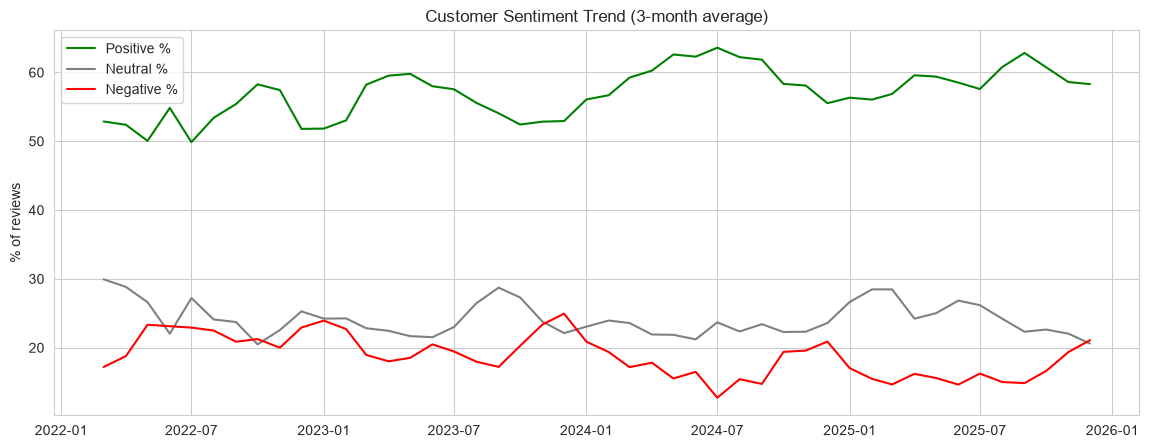

In [2]:
df["Month"] = df["Review Date"].dt.to_period("M")
monthly = pd.crosstab(df["Month"], df["Sentiment"], normalize="index") * 100
monthly.index = monthly.index.to_timestamp()

smooth = monthly.rolling(3).mean()     # 3-month average to smooth the ups and downs

plt.figure(figsize=(14, 5))
plt.plot(smooth.index, smooth["Positive"], color="green", label="Positive %")
plt.plot(smooth.index, smooth["Neutral"], color="gray", label="Neutral %")
plt.plot(smooth.index, smooth["Negative"], color="red", label="Negative %")
plt.title("Customer Sentiment Trend (3-month average)")
plt.ylabel("% of reviews")
plt.legend()
plt.show()

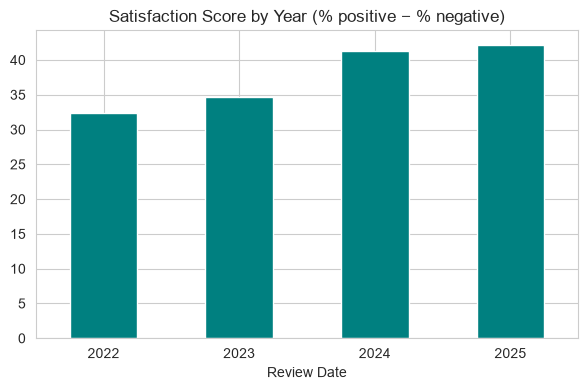

Review Date
2022    32.4
2023    34.7
2024    41.3
2025    42.2
Name: Satisfaction, dtype: float64


In [3]:
df["Satisfaction"] = (df["Sentiment"] == "Positive").astype(int) - (df["Sentiment"] == "Negative").astype(int)
score = df.groupby(df["Review Date"].dt.year)["Satisfaction"].mean() * 100

score.plot(kind="bar", color="teal", figsize=(7, 4))
plt.title("Satisfaction Score by Year (% positive − % negative)")
plt.xticks(rotation=0)
plt.show()

print(score.round(1))

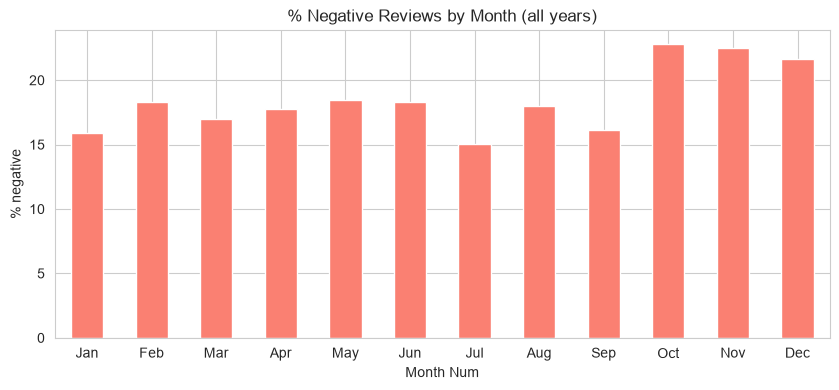

In [4]:
df["Month Num"] = df["Review Date"].dt.month
neg_month = (df["Sentiment"] == "Negative").groupby(df["Month Num"]).mean() * 100

neg_month.plot(kind="bar", color="salmon", figsize=(10, 4))
plt.title("% Negative Reviews by Month (all years)")
plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
plt.ylabel("% negative")
plt.show()

In [5]:
city = df.groupby("City").agg(
    Reviews=("Sentiment", "size"),
    Positive_pct=("Sentiment", lambda s: (s == "Positive").mean() * 100),
    Negative_pct=("Sentiment", lambda s: (s == "Negative").mean() * 100),
).round(1)

print("Most negative cities:")
print(city.sort_values("Negative_pct", ascending=False).head(5))
print("\nMost satisfied cities:")
print(city.sort_values("Negative_pct").head(3))

Most negative cities:
             Reviews  Positive_pct  Negative_pct
City                                            
Ranchi            62          45.2          32.3
Bhubaneswar      122          52.5          29.5
Guwahati         163          50.9          23.3
Patna            148          51.4          23.0
Kolkata          318          51.3          21.7

Most satisfied cities:
            Reviews  Positive_pct  Negative_pct
City                                           
Coimbatore      257          64.2          15.2
New Delhi       504          59.5          16.9
Bengaluru      1505          57.9          17.6


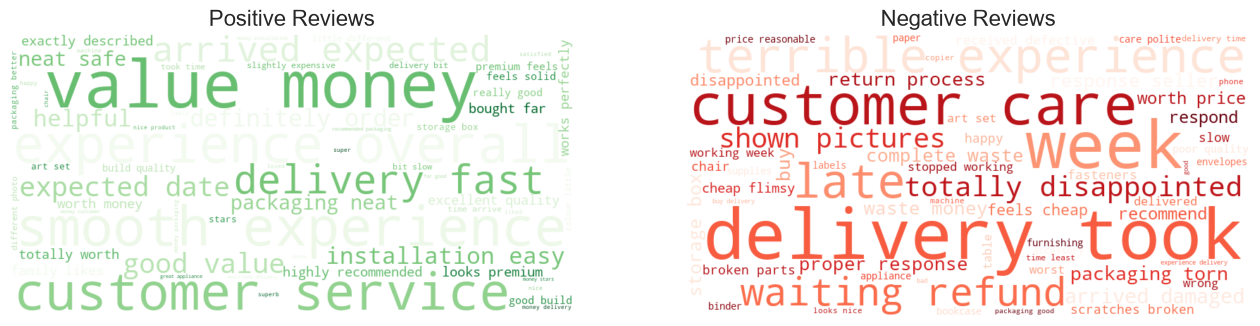

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

for i, (sentiment, color) in enumerate([("Positive", "Greens"), ("Negative", "Reds")]):
    text = " ".join(df[df["Sentiment"] == sentiment]["Clean Text"])
    wc = WordCloud(width=800, height=400, background_color="white",
                   colormap=color, max_words=60).generate(text)
    ax[i].imshow(wc, interpolation="bilinear")
    ax[i].axis("off")
    ax[i].set_title(f"{sentiment} Reviews", fontsize=16)

plt.show()

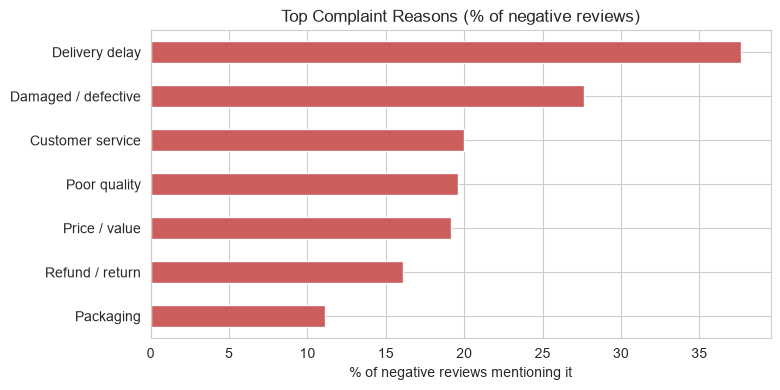

Packaging              11.1
Refund / return        16.1
Price / value          19.1
Poor quality           19.6
Customer service       20.0
Damaged / defective    27.6
Delivery delay         37.7
dtype: float64


In [7]:
themes = {
    "Delivery delay":      ["late", "delay", "week", "took", "waiting"],
    "Damaged / defective": ["damaged", "defective", "broken", "scratches", "stopped working"],
    "Poor quality":        ["poor quality", "cheap", "flimsy", "worst"],
    "Packaging":           ["packaging", "torn"],
    "Refund / return":     ["refund", "return"],
    "Customer service":    ["customer care", "respond", "response", "service"],
    "Price / value":       ["price", "waste money", "overpriced", "expensive"],
}

neg = df[df["Sentiment"] == "Negative"]
theme_share = pd.Series({
    theme: neg["Clean Text"].apply(lambda text: any(k in text for k in keywords)).mean() * 100
    for theme, keywords in themes.items()
}).sort_values()

theme_share.plot(kind="barh", color="indianred", figsize=(8, 4))
plt.title("Top Complaint Reasons (% of negative reviews)")
plt.xlabel("% of negative reviews mentioning it")
plt.show()

print(theme_share.round(1))